# Import Library & Import Data

In [1]:
# Data Processing
import pandas as pd
import numpy as np

# Data Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Datetime Standardize
import datetime

In [2]:
import sys
import matplotlib

print(f"Python version: {sys.version.split()[0]}")
print(f"pandas version: {pd.__version__}")
print(f"matplotlib version: {matplotlib.__version__}")
print(f"numpy version: {np.__version__}")

Python version: 3.13.15
pandas version: 2.2.3
matplotlib version: 3.10.0
numpy version: 2.1.3


In [3]:
df = pd.read_csv('/content/drive/MyDrive/Khóa học "Project-based Learning"/K04 - Scripts các buổi học/Dataset/Online Retail.csv')
df.head(2)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/10 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/10 8:26,3.39,17850.0,United Kingdom


# Data Checking

In [ ]:
# Check metadata

In [ ]:
# Check data types

In [ ]:
# Check dup

In [ ]:
# Check NA

In [ ]:
# Check outliers

# Data Preprocessing / Wrangling

In [ ]:
# Solve data types

In [ ]:
# Solve dup

In [ ]:
# Solve NA

In [ ]:
# Solve outliers

# Exploratory Data Analysis

In [6]:
df_prep = df[['CustomerID', 'InvoiceDate']].drop_duplicates()
df_prep.head()

,CustomerID,InvoiceDate
0,17850.0,12/1/10 8:26
7,17850.0,12/1/10 8:28
9,13047.0,12/1/10 8:34
25,13047.0,12/1/10 8:35
26,12583.0,12/1/10 8:45


In [7]:
df_prep.isna().sum()

,0
CustomerID,3161
InvoiceDate,0


In [9]:
df_prep_notna = df_prep.dropna()
df_prep_notna

,CustomerID,InvoiceDate
0,17850.0,12/1/10 8:26
7,17850.0,12/1/10 8:28
9,13047.0,12/1/10 8:34
25,13047.0,12/1/10 8:35
26,12583.0,12/1/10 8:45
...,...,...
541865,13777.0,12/9/11 12:23
541867,13777.0,12/9/11 12:25
541869,15804.0,12/9/11 12:31
541890,13113.0,12/9/11 12:49


In [11]:
df_prep_notna['InvoiceDate'] = df_prep_notna['InvoiceDate'].astype('datetime64[ns]')

# pd.to_datetime

df_prep_notna

/tmp/ipykernel_556/2861718529.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_prep_notna['InvoiceDate'] = df_prep_notna['InvoiceDate'].astype('datetime64[ns]')


,CustomerID,InvoiceDate
0,17850.0,2010-12-01 08:26:00
7,17850.0,2010-12-01 08:28:00
9,13047.0,2010-12-01 08:34:00
25,13047.0,2010-12-01 08:35:00
26,12583.0,2010-12-01 08:45:00
...,...,...
541865,13777.0,2011-12-09 12:23:00
541867,13777.0,2011-12-09 12:25:00
541869,15804.0,2011-12-09 12:31:00
541890,13113.0,2011-12-09 12:49:00


In [12]:
# Bước 1: Tìm lần mua đầu tiên của các khách hàng ==> GROUP BY + MIN(InvoiceDate)

df_customer_first_order = df_prep_notna.groupby(by = 'CustomerID', as_index = False).agg(first_order_date = ('InvoiceDate', 'min'))
df_customer_first_order

,CustomerID,first_order_date
0,12346.0,2011-01-18 10:01:00
1,12347.0,2010-12-07 14:57:00
2,12348.0,2010-12-16 19:09:00
3,12349.0,2011-11-21 09:51:00
4,12350.0,2011-02-02 16:01:00
...,...,...
4367,18280.0,2011-03-07 09:52:00
4368,18281.0,2011-06-12 10:53:00
4369,18282.0,2011-08-05 13:35:00
4370,18283.0,2011-01-06 14:14:00


In [15]:
# Bước 2: Nối để tính khoảng cách thời gian

df_prep_cohort = df_prep_notna.merge(df_customer_first_order, on = 'CustomerID', how = 'inner')
df_prep_cohort.head()

,CustomerID,InvoiceDate,first_order_date
0,17850.0,2010-12-01 08:26:00,2010-12-01 08:26:00
1,17850.0,2010-12-01 08:28:00,2010-12-01 08:26:00
2,13047.0,2010-12-01 08:34:00,2010-12-01 08:34:00
3,13047.0,2010-12-01 08:35:00,2010-12-01 08:34:00
4,12583.0,2010-12-01 08:45:00,2010-12-01 08:45:00


In [18]:
# Tính khoảng cách thời gian
df_prep_cohort['month_diff'] = (df_prep_cohort['InvoiceDate'].dt.year - df_prep_cohort['first_order_date'].dt.year) * 12 + (df_prep_cohort['InvoiceDate'].dt.month - df_prep_cohort['first_order_date'].dt.month)
df_prep_cohort['first_month'] = df_prep_cohort['first_order_date'].dt.to_period('M')

df_prep_cohort

,CustomerID,InvoiceDate,first_order_date,month_diff,first_month
0,17850.0,2010-12-01 08:26:00,2010-12-01 08:26:00,0,2010-12
1,17850.0,2010-12-01 08:28:00,2010-12-01 08:26:00,0,2010-12
2,13047.0,2010-12-01 08:34:00,2010-12-01 08:34:00,0,2010-12
3,13047.0,2010-12-01 08:35:00,2010-12-01 08:34:00,0,2010-12
4,12583.0,2010-12-01 08:45:00,2010-12-01 08:45:00,0,2010-12
...,...,...,...,...,...
22029,13777.0,2011-12-09 12:23:00,2010-12-01 16:01:00,12,2010-12
22030,13777.0,2011-12-09 12:25:00,2010-12-01 16:01:00,12,2010-12
22031,15804.0,2011-12-09 12:31:00,2011-05-25 10:12:00,7,2011-05
22032,13113.0,2011-12-09 12:49:00,2010-12-08 13:07:00,12,2010-12


In [20]:
# Tạo ra Matrix / Pivot table ==> Cohort

df_cohort = df_prep_cohort.pivot_table(index = 'first_month' ,
                           columns = 'month_diff' ,
                           values = 'CustomerID' ,
                           aggfunc = 'nunique'
)
df_cohort

month_diff,0,1,2,3,4,5,6,7,8,9,10,11,12
first_month,,,,,,,,,,,,,
2010-12,948.0,362.0,317.0,367.0,341.0,376.0,360.0,336.0,336.0,374.0,354.0,474.0,260.0
2011-01,421.0,101.0,119.0,102.0,138.0,126.0,110.0,108.0,131.0,146.0,155.0,63.0,NaN
2011-02,380.0,94.0,73.0,106.0,102.0,94.0,97.0,107.0,98.0,119.0,35.0,NaN,NaN
2011-03,440.0,84.0,112.0,96.0,102.0,78.0,116.0,105.0,127.0,39.0,NaN,NaN,NaN
2011-04,299.0,68.0,66.0,63.0,62.0,71.0,69.0,78.0,25.0,NaN,NaN,NaN,NaN
2011-05,279.0,66.0,48.0,48.0,60.0,68.0,74.0,29.0,NaN,NaN,NaN,NaN,NaN
2011-06,235.0,49.0,44.0,64.0,58.0,79.0,24.0,NaN,NaN,NaN,NaN,NaN,NaN
2011-07,191.0,40.0,39.0,44.0,52.0,22.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2011-08,167.0,42.0,42.0,42.0,23.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


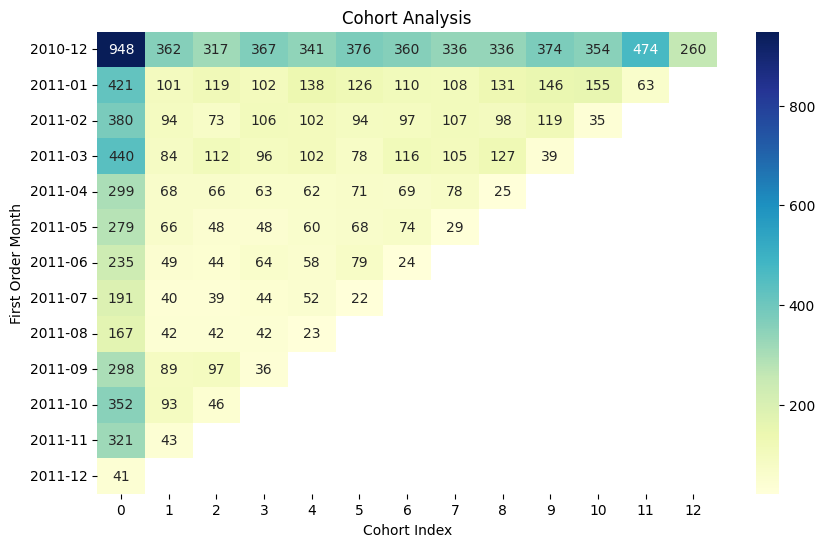

In [21]:
plt.figure(figsize= (10,6))
sns.heatmap(data = df_cohort
            ,annot=True
            ,cmap='YlGnBu'
            ,fmt = 'g'
            )

plt.xlabel('Cohort Index')
plt.ylabel('First Order Month')
plt.title('Cohort Analysis')

plt.show()

In [22]:
df_cohort_new = df_cohort
empty_column = pd.Series([0] * len(df_cohort_new), name='SLKH')
df_cohort_new.insert(loc=0, column='SLKH', value=empty_column)

cohort_size_monthly_new = df_cohort_new.iloc[:, 1]
retention_matrix_monthly_new = df_cohort_new.divide(cohort_size_monthly_new, axis=0)
retention_matrix_monthly_new

month_diff,SLKH,0,1,2,3,4,5,6,7,8,9,10,11,12
first_month,,,,,,,,,,,,,,
2010-12,NaN,1.0,0.381857,0.334388,0.387131,0.359705,0.396624,0.379747,0.354430,0.354430,0.394515,0.373418,0.500000,0.274262
2011-01,NaN,1.0,0.239905,0.282660,0.242280,0.327791,0.299287,0.261283,0.256532,0.311164,0.346793,0.368171,0.149644,NaN
2011-02,NaN,1.0,0.247368,0.192105,0.278947,0.268421,0.247368,0.255263,0.281579,0.257895,0.313158,0.092105,NaN,NaN
2011-03,NaN,1.0,0.190909,0.254545,0.218182,0.231818,0.177273,0.263636,0.238636,0.288636,0.088636,NaN,NaN,NaN
2011-04,NaN,1.0,0.227425,0.220736,0.210702,0.207358,0.237458,0.230769,0.260870,0.083612,NaN,NaN,NaN,NaN
2011-05,NaN,1.0,0.236559,0.172043,0.172043,0.215054,0.243728,0.265233,0.103943,NaN,NaN,NaN,NaN,NaN
2011-06,NaN,1.0,0.208511,0.187234,0.272340,0.246809,0.336170,0.102128,NaN,NaN,NaN,NaN,NaN,NaN
2011-07,NaN,1.0,0.209424,0.204188,0.230366,0.272251,0.115183,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2011-08,NaN,1.0,0.251497,0.251497,0.251497,0.137725,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


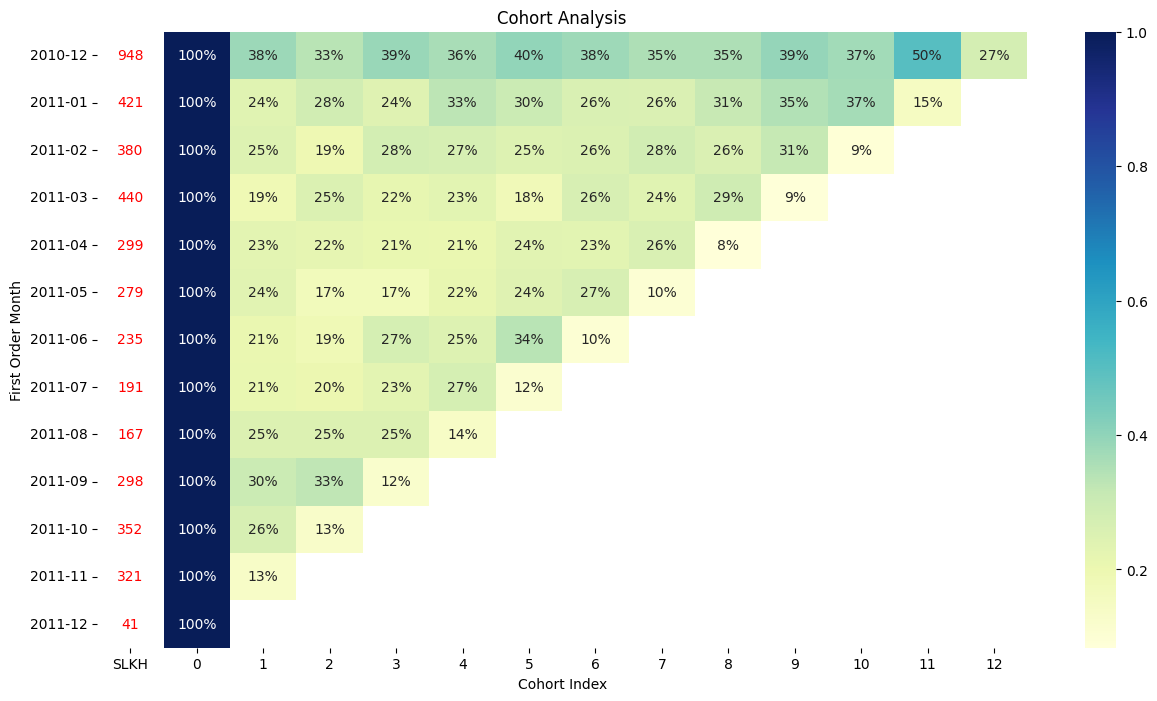

In [25]:
plt.figure(figsize= (15,8))
sns.heatmap(data = retention_matrix_monthly_new
            ,annot=True
            ,cmap='YlGnBu'
            ,fmt = '.0%'
            )

for i in range(len(df_cohort)):
    plt.text(0.5, i + 0.5, '{:,.0f}'.format(df_cohort.iloc[i, 1])
            , ha='center'
            , va='center'
            , color = 'red')

plt.xlabel('Cohort Index')
plt.ylabel('First Order Month')
plt.title('Cohort Analysis')

plt.show()

# Feature Engineering

# Optional: Split Train Test

# Optional: Model Evaluation & Cross Validation

# Conclusion & Recommendation